# RL agent sims (260914): model characterisation by centrality strategy

30 social (2-agent) self-play models trained in `Octagon/results/2609/260914`. Per `notes.txt`
this batch changed several training parameters to try to improve learning, so it is not a seed
replicate of 260723:

| setting | 260723 | 260914 |
| --- | --- | --- |
| extrinsic gamma | 0.99 | 0.998 |
| lambd | 0.95 | 0.99 |
| time_horizon | 128 | 512 |
| learning_rate / epsilon schedule | linear | constant |
| max_steps | 4e6 | 7e6 |

The gamma increase is expected to matter most, as it cuts the temporal discounting of future
reward. The penalty-break clause is out of this build, as it was for 260723, so the resting
metrics are directly comparable between the two batches.

**The characterisation axis is centrality at slice onset.** For each trial, at the frame the
walls appear, centrality `= 1 - r/R` (1 = arena centre, 0 = at a wall). A model's mean over
trials is roughly where it stands when the trial starts.

260723 split cleanly into a central and a peripheral group. This batch does not: 27 of the 30
models sit in one tight central band, and three sit below it on their own. So there is no
strategy split to compare across, and the notebook instead asks how much the models vary
**within** that one cluster, and which metrics do the varying.

**Plan**
1. **The strategy axis** — per-model slice-onset centrality, and whether it splits.
2. **Within-batch variability** — which fingerprint metrics spread the models and which are flat.
3. **Multivariate fingerprint** — whether centrality is still the main axis once every metric is in.
4. **Against 260723** — how the central group moved.

No tournament shortlist here. This batch is being characterised, not picked from.

**Choices** (matching prior sim notebooks): FoV = 110.0; both agents pooled (self-play);
everything that computes a number comes from `analysis/model_characterisation.py`.

### Results:
- The strategy split is gone. 27 of 30 models sit at onset centrality 0.81-0.91; only models 17
  (0.14), 10 (0.46) and 19 (0.68) fall below. 260723 had a whole peripheral group
- Position barely moved for the central group (0.849 -> 0.873 onset centrality), but High-wall
  choice jumped: p_high 0.862 -> 0.975, mean_score 0.462 -> 0.501
- Latency, path length and visibility at onset are all unchanged from 260723 central
- Resting rose slightly on average (0.027 -> 0.053), but that is three models pulling the mean.
  The median model rests less than 0.03
- Nearly all the within-cluster spread is in the resting and scanning metrics. Models 3, 2 and 24
  rest and stand still far more than the other 24
- The three off-cluster models move the most of the whole batch (lowest resting, longest ITI path)
- Model 16's simulation hung after its last slice onset, leaving 53 usable trials against 198
  for every other model. Its numbers are noisier, not wrong- With the centrality columns out, PC1 explains only 38% and barely tracks centrality
  (r = -0.30). Resting and scanning, not position, organise this batch


In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import data_strings
import analysis.model_characterisation as mc
import plotting.plot_octagon as plot_octagon

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

# social self-play inference logs for this run live in a dated subfolder
SIM_DATA_FOLDER = os.path.join(data_strings.SIM_DATA_FOLDER, '2609', '260914')

CURRENT_FOV = 110.0                 # agent camera FoV (total degrees)

In [2]:
# every run in this batch trained for 7e6 steps, so there is no training-length split
ALL_MODELS = mc.get_batch_models(SIM_DATA_FOLDER)
print(f"models found: {len(ALL_MODELS)}")
print(ALL_MODELS)

models found: 30
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]


## Main pass over all models

One pass per model builds the long tables: `slice` (slice-onset centrality and x,z, one row per
trial x agent), `iti`, `vis`, `score` and `rt`. Each model is loaded, measured, then discarded,
so the batch stays memory-safe. Slice-onset x,z are kept for the occupancy heatmaps further
down. Runs with no completed trials are skipped.

In [3]:
tables = mc.collect_model_data(SIM_DATA_FOLDER, models=ALL_MODELS, fov=CURRENT_FOV)
USABLE_MODELS = mc.summarise_collection(tables, ALL_MODELS)
slice_df, iti_df = tables['slice'], tables['iti']

model  1 done  

model  2 done  

model  3 done  

model  4 done  

model  5 done  

...

model 26 done  

model 27 done  

model 28 done  

model 29 done  

model 30 done  

usable models: 30 / 30
slice-onset rows: 11590 | ITIs: 11590 | visibility rows: 11590 | scored trials: 5795
trials per model: min 53, max 198


### Trial counts per model

Every model should contribute the same number of trials. One that contributes far fewer had its
simulation cut short, and its per-model means rest on less data.

In [4]:
# count the trials each model contributed, pooled over both agents
n_trials = (slice_df.groupby('model').size() // len(mc.PLAYERS)).rename('n_trials')
short = n_trials[n_trials < 0.9 * n_trials.median()]
print(f"trials per model: median {int(n_trials.median())}, min {int(n_trials.min())}")
if len(short):
    print("\nmodels with a short run:")
    print(short.to_string())

trials per model: median 198, min 53

models with a short run:
model
16    53


## Stage 1 - the strategy axis (centrality at slice onset)

Each model's mean slice-onset centrality summarises its strategy. Models are ranked by it
(bar = mean, whisker = SD across trials), with the spread of individual trials shown below. A
tight spread means the model starts most trials from a similar distance out; a wide one means
its start position varies a lot.

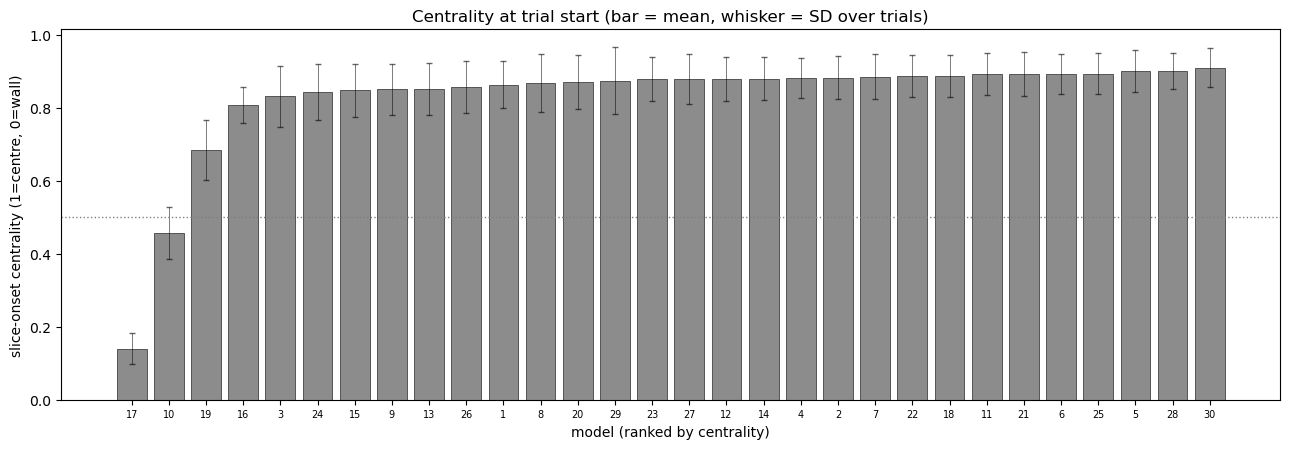

In [5]:
onset_by_model = mc.onset_centrality_by_model(slice_df)

order = onset_by_model.sort_values('onset_centrality').reset_index(drop=True)
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.bar(x, order['onset_centrality'], yerr=order['onset_sd'], capsize=2,
       color='#8C8C8C', edgecolor='black', linewidth=0.4,
       error_kw=dict(lw=0.6, alpha=0.6))

ax.axhline(0.5, color='grey', ls=':', lw=1)
ax.set_xticks(x); ax.set_xticklabels(order['model'], fontsize=7)
ax.set_xlabel('model (ranked by centrality)'); ax.set_ylabel('slice-onset centrality (1=centre, 0=wall)')
ax.set_title('Centrality at trial start (bar = mean, whisker = SD over trials)')
plt.tight_layout(); plt.show()

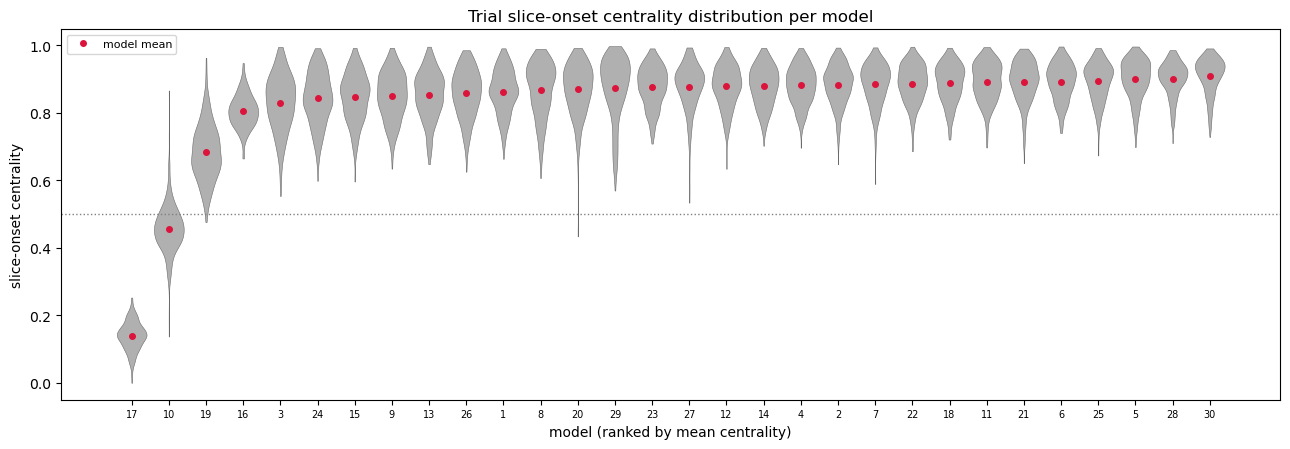

In [6]:
# plot the per-trial spread within each model, ordered by model mean
fig, ax = plt.subplots(figsize=(13, 4.6))
mean_order = onset_by_model.sort_values('onset_centrality')['model'].tolist()
sns.violinplot(data=slice_df, x='model', y='centrality', order=mean_order,
               density_norm='width', inner=None, cut=0, linewidth=0.4,
               color='#B0B0B0', ax=ax)
ax.plot(range(len(mean_order)),
        onset_by_model.set_index('model').loc[mean_order, 'onset_centrality'].values,
        'o', color='crimson', markersize=4, label='model mean')
ax.axhline(0.5, color='grey', ls=':', lw=1)
ax.set_xticks(range(len(mean_order)))
ax.set_xticklabels(mean_order, fontsize=7)
ax.set_xlabel('model (ranked by mean centrality)'); ax.set_ylabel('slice-onset centrality')
ax.set_title('Trial slice-onset centrality distribution per model')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### One cluster, not two

The same split used on 260723 is run here for comparison: a fixed cut at centrality = 0.5, and a
Gaussian mixture that finds its own boundary. Both are kept only to show that neither finds two
populations. The mixture does separate the low models, but that low component holds three models
against twenty-seven, which is a handful of stragglers rather than a second strategy.

GMM component means: [0.482 0.874]  weights: [0.12 0.88]
fixed(0.5) vs GMM agreement: 97%
strategy_gmm  strategy_fixed
central       central           27
peripheral    central            1
              peripheral         2
Name: n, dtype: int64


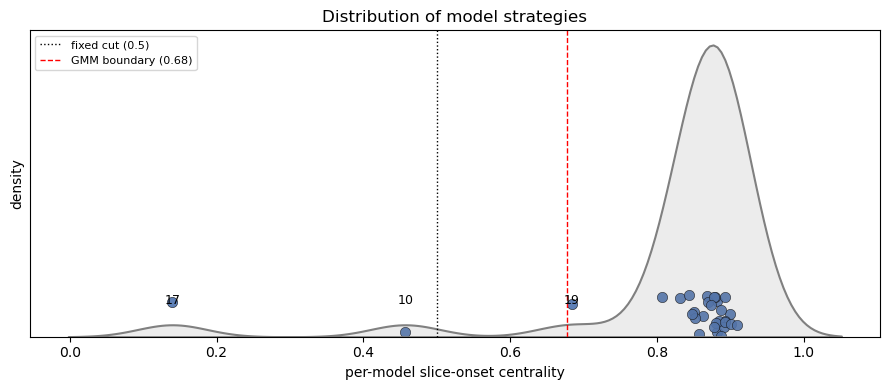

In [7]:
onset_by_model, gmm, boundary = mc.split_strategies(onset_by_model)
mc.report_strategy_split(onset_by_model, gmm)

vals = onset_by_model['onset_centrality'].to_numpy()
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(vals, np.random.uniform(0, 1, len(vals)),
           color='#4C72B0', edgecolor='black', linewidth=0.4, s=55, alpha=0.9)
# label the models sitting away from the main band
for _, r in onset_by_model[onset_by_model['onset_centrality'] < 0.75].iterrows():
    ax.annotate(int(r['model']), (r['onset_centrality'], 0.5), fontsize=9,
                xytext=(0, 8), textcoords='offset points', ha='center')
sns.kdeplot(x=vals, ax=ax, color='grey', lw=1.5, fill=True, alpha=0.15, bw_adjust=0.6)
ax.axvline(0.5, color='black', ls=':', lw=1, label='fixed cut (0.5)')
ax.axvline(boundary, color='red', ls='--', lw=1, label=f'GMM boundary ({boundary:.2f})')
ax.set_yticks([]); ax.set_xlabel('per-model slice-onset centrality'); ax.set_ylabel('density')
ax.set_title('Distribution of model strategies')
ax.legend(fontsize=8, loc='upper left'); plt.tight_layout(); plt.show()

### Main cluster and off-cluster models

The batch is treated as one group plus a few named exceptions. Models more than `OUTLIER_CUT`
below the main band are held out of every group mean and spread statistic, because a group of one
model cannot support a group statistic. They stay in the fingerprint table and are drawn as
labelled points, so nothing is hidden.

In [8]:
OUTLIER_CUT = 0.75                  # below the main band, which starts at 0.81

model_meta = mc.build_model_meta(USABLE_MODELS, onset_by_model, strategy_col='strategy')
model_meta['group'] = np.where(model_meta['onset_centrality'] < OUTLIER_CUT, 'off-cluster', 'main')

MAIN = model_meta.loc[model_meta['group'] == 'main', 'model'].astype(int).tolist()
OUTLIERS = model_meta.loc[model_meta['group'] == 'off-cluster', 'model'].astype(int).tolist()
# colour each off-cluster model separately, as each one is read on its own
OUT_COLOURS = dict(zip(OUTLIERS, ['#DD8452', '#C44E52', '#8172B3']))

print(f"main cluster (n={len(MAIN)}): {MAIN}")
print(f"off-cluster  (n={len(OUTLIERS)}): {OUTLIERS}")
print()
print(model_meta.loc[model_meta['group'] == 'off-cluster',
                     ['model', 'onset_centrality', 'strategy_gmm', 'strategy']].round(3).to_string(index=False))

main cluster (n=27): [1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14, 15, 16, 18, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
off-cluster  (n=3): [10, 17, 19]

 model  onset_centrality strategy_gmm     strategy
    10             0.457   peripheral intermediate
    17             0.140   peripheral   peripheral
    19             0.684   peripheral intermediate


## Stage 2 - within-batch variability

With one cluster there is nothing to compare between groups, so the question becomes how much the
models differ from each other at all. For each fingerprint metric, the spread across the 27
main-cluster models is summarised and ranked. A metric with a wide spread tells otherwise-similar
models apart; a flat one is fixed by the task.

CV (SD / |mean|) is the scale-free measure, but it blows up wherever the mean sits near zero, so
read `frac_never_visible` and `frac_trials_over_5s` from their min and max instead.

In [9]:
fingerprint = mc.build_fingerprint(model_meta, tables)
fingerprint[['model', 'group'] + mc.FP_METRICS].round(3)

,model,group,onset_centrality,iti_centrality,prop_no_translational,prop_no_rotational,proportion_resting,iti_path_len,rot_total,winner_path_len,path_ratio,frac_visible_at_onset,late_latency_to_wall_visible,all_latency_to_wall_visible,latency_to_reach_wall,frac_never_visible,frac_trials_over_5s,p_high,mean_score,score_rate
0,1,main,0.863,0.773,0.314,0.193,0.060,33.933,1448.310,21.032,1.165,0.720,0.225,0.063,2.167,0.000,0.000,1.000,0.540,0.463
1,2,main,0.882,0.816,0.553,0.345,0.183,21.849,1176.400,20.780,1.160,0.652,0.326,0.114,2.124,0.000,0.000,1.000,0.530,0.462
2,3,main,0.831,0.771,0.590,0.689,0.431,20.085,546.437,21.947,1.172,0.669,1.346,0.422,2.240,0.025,0.010,1.000,0.465,0.401
3,4,main,0.882,0.858,0.203,0.160,0.039,39.181,1504.273,20.440,1.144,0.677,0.275,0.089,2.010,0.000,0.005,1.000,0.510,0.481
4,5,main,0.900,0.871,0.109,0.389,0.047,43.910,1092.110,20.541,1.145,0.674,0.373,0.122,2.053,0.000,0.000,1.000,0.515,0.483
5,6,main,0.893,0.870,0.191,0.248,0.045,39.930,1353.655,20.027,1.116,0.710,0.250,0.073,2.013,0.000,0.000,1.000,0.470,0.493
6,7,main,0.885,0.827,0.092,0.247,0.026,44.954,1353.946,21.149,1.188,0.712,0.241,0.069,2.124,0.000,0.000,1.000,0.470,0.468
7,8,main,0.868,0.788,0.371,0.125,0.038,30.979,1570.764,19.811,1.110,0.692,0.253,0.078,2.060,0.000,0.000,1.000,0.520,0.487
8,9,main,0.851,0.820,0.054,0.173,0.012,46.785,1481.746,20.273,1.140,0.702,0.271,0.081,2.054,0.000,0.000,1.000,0.586,0.487
9,10,off-cluster,0.457,0.493,0.017,0.292,0.007,48.819,1267.673,20.590,1.265,0.490,1.318,0.629,1.760,0.063,0.035,0.742,0.402,0.403


In [10]:
# summarise how far the main-cluster models spread on each metric, ranked by CV
fp_main = fingerprint[fingerprint['group'] == 'main']
spread = fp_main[mc.FP_METRICS].agg(['mean', 'std', 'min', 'max']).T
spread['cv'] = spread['std'] / spread['mean'].abs()
spread = spread.rename_axis('metric').reset_index().sort_values('cv', ascending=False)
print(f"spread across the {len(fp_main)} main-cluster models (ranked by CV)")
spread.round(3)

spread across the 27 main-cluster models (ranked by CV)


,metric,mean,std,min,max,cv
14,frac_trials_over_5s,0.001,0.002,0.000,0.010,3.078
13,frac_never_visible,0.003,0.009,0.000,0.040,2.885
4,proportion_resting,0.053,0.084,0.008,0.431,1.595
2,prop_no_translational,0.187,0.165,0.025,0.590,0.879
11,all_latency_to_wall_visible,0.107,0.087,0.063,0.422,0.814
10,late_latency_to_wall_visible,0.341,0.277,0.199,1.346,0.811
3,prop_no_rotational,0.229,0.144,0.071,0.689,0.628
5,iti_path_len,40.041,8.174,20.085,47.962,0.204
6,rot_total,1383.387,260.357,546.437,1663.655,0.188
16,mean_score,0.501,0.045,0.394,0.586,0.090


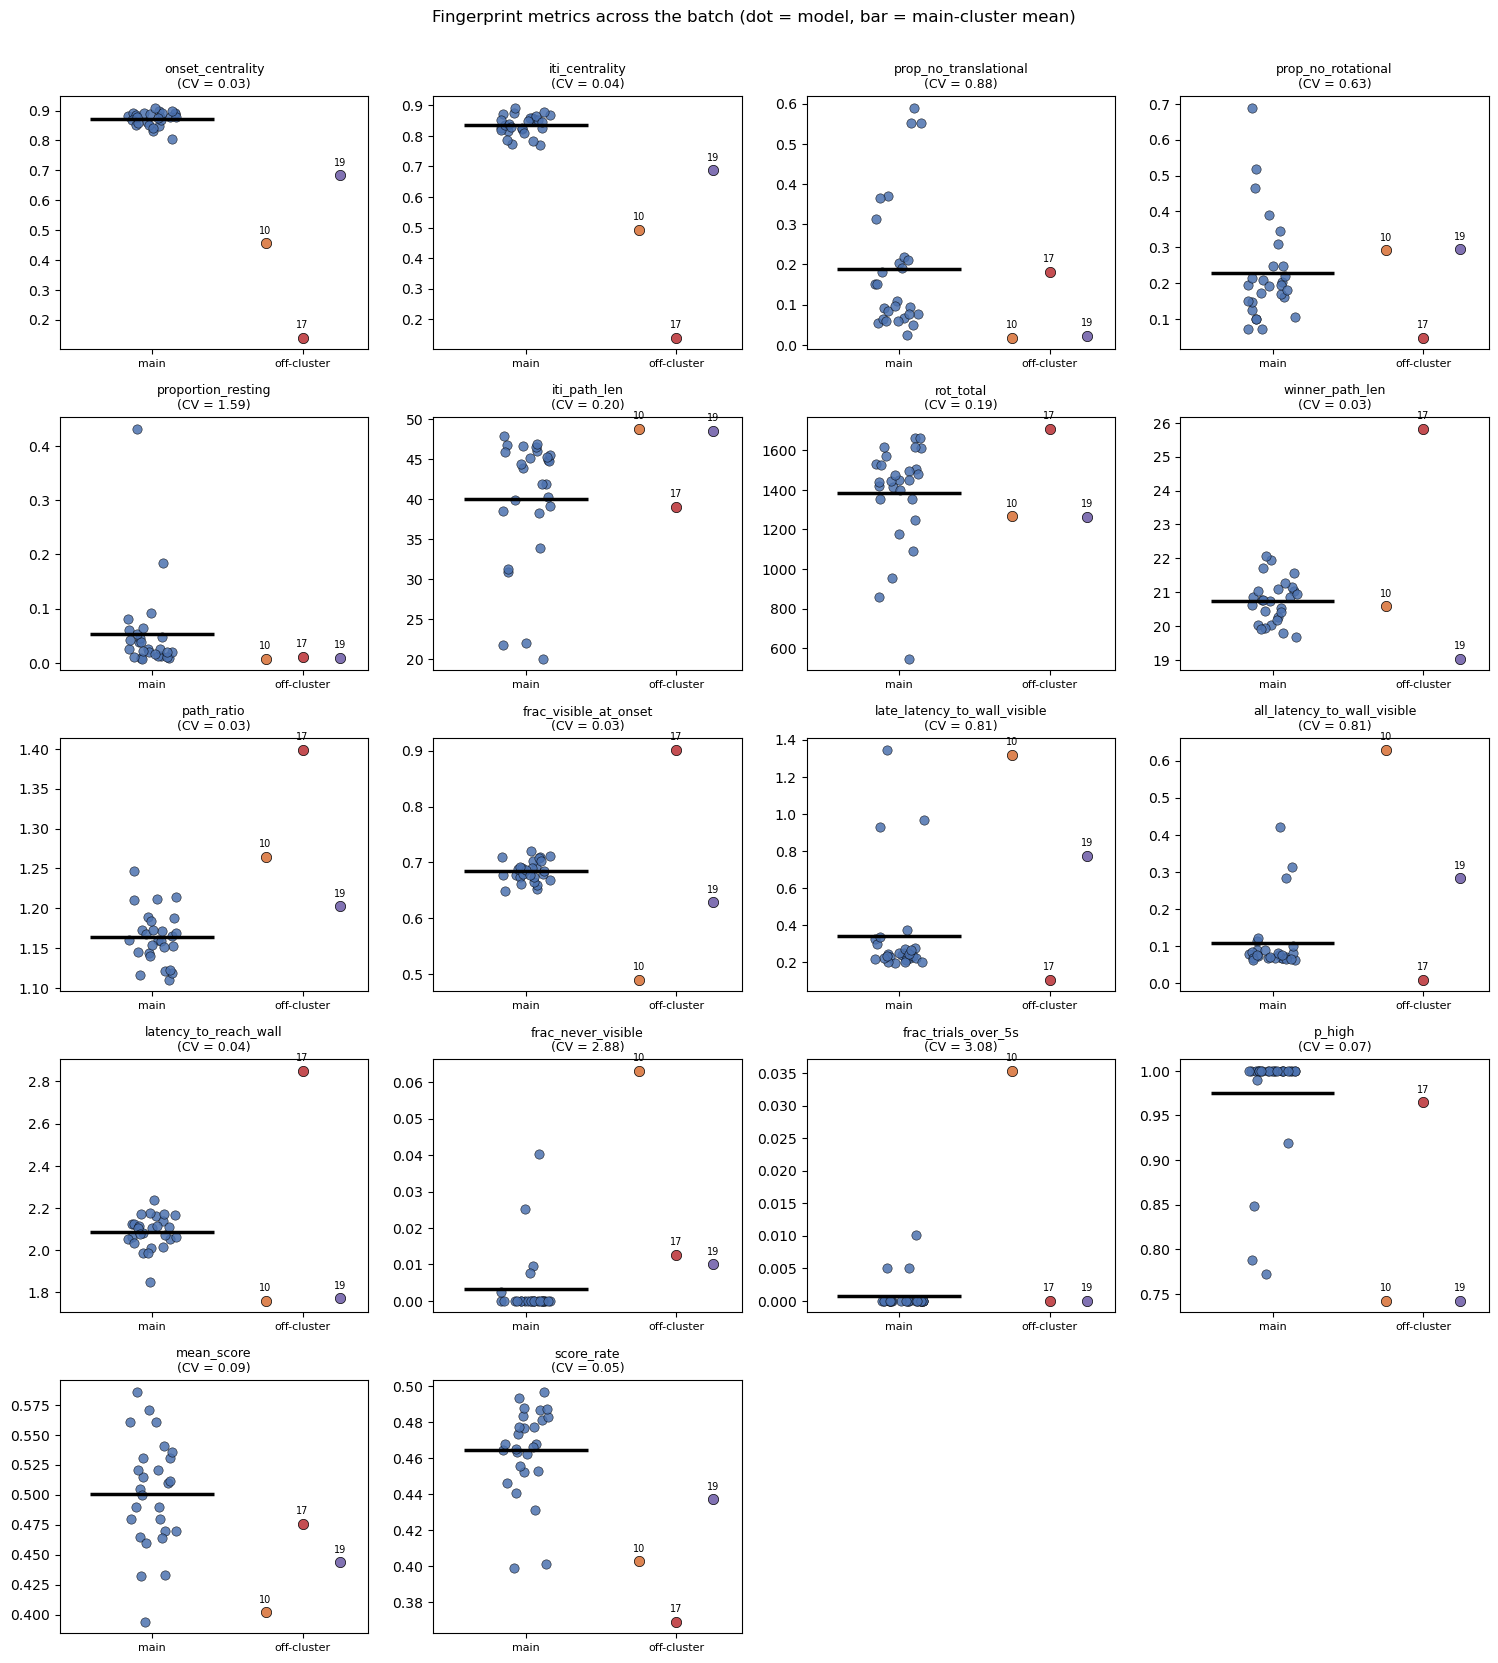

In [11]:
# plot every model on each metric. Main-cluster models are one colour, off-cluster models are
# labelled, so a metric where the stragglers are extreme is visible straight away
ncol = 4
nrow = int(np.ceil(len(mc.FP_METRICS) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.3 * nrow))
cv_by_metric = spread.set_index('metric')['cv']
for ax, m in zip(axes.ravel(), mc.FP_METRICS):
    ax.scatter(np.random.uniform(-0.12, 0.12, len(fp_main)), fp_main[m],
               s=45, color='#4C72B0', edgecolor='black', linewidth=0.4, alpha=0.85)
    ax.hlines(fp_main[m].mean(), -0.3, 0.3, color='black', lw=2.5, zorder=5)
    # draw each off-cluster model as its own labelled point
    for i, mod in enumerate(OUTLIERS):
        v = fingerprint.loc[fingerprint['model'] == mod, m].iloc[0]
        ax.scatter([0.55 + 0.18 * i], [v], s=55, color=OUT_COLOURS[mod],
                   edgecolor='black', linewidth=0.5, zorder=6)
        ax.annotate(mod, (0.55 + 0.18 * i, v), fontsize=7, xytext=(0, 7),
                    textcoords='offset points', ha='center')
    ax.set_xlim(-0.45, 1.05); ax.set_xticks([0, 0.73])
    ax.set_xticklabels(['main', 'off-cluster'], fontsize=8)
    ax.set_title(f'{m}\n(CV = {cv_by_metric[m]:.2f})', fontsize=9)
for ax in axes.ravel()[len(mc.FP_METRICS):]:
    ax.axis('off')
plt.suptitle('Fingerprint metrics across the batch (dot = model, bar = main-cluster mean)', y=1.005)
plt.tight_layout(); plt.show()

### The models that drive the spread

The top metrics by CV are all resting and scanning measures. These list which models sit at the
extremes, to check whether the spread is a handful of models or a genuine continuum.

In [12]:
# rank only the metrics whose median sits clear of zero. CV around a near-zero mean is not
# comparable, which is what puts frac_never_visible and frac_trials_over_5s at the top of the table
solid = [m for m in spread['metric'] if fp_main[m].median() > 0]
TOP_N = 4
for m in [m for m in spread['metric'] if m in solid][:TOP_N]:
    s = fp_main.set_index('model')[m].sort_values(ascending=False)
    print(f"{m}  (median {s.median():.3f})")
    print(f"   highest: {', '.join(f'{int(i)}={v:.3f}' for i, v in s.head(3).items())}")
    print(f"   lowest : {', '.join(f'{int(i)}={v:.3f}' for i, v in s.tail(3).items())}")
    print()


proportion_resting  (median 0.026)
   highest: 3=0.431, 2=0.183, 16=0.092
   lowest : 12=0.009, 14=0.009, 18=0.008

prop_no_translational  (median 0.109)
   highest: 3=0.590, 2=0.553, 24=0.551
   lowest : 9=0.054, 28=0.048, 12=0.025

all_latency_to_wall_visible  (median 0.075)
   highest: 3=0.422, 15=0.313, 16=0.283
   lowest : 18=0.064, 24=0.064, 1=0.063

late_latency_to_wall_visible  (median 0.243)
   highest: 3=1.346, 15=0.967, 16=0.928
   lowest : 14=0.201, 24=0.199, 23=0.199



### Where the models stand at slice onset

Occupancy of the slice-onset position, with the octagon outline. The main cluster is pooled over
its 27 models, and each off-cluster model gets its own panel.

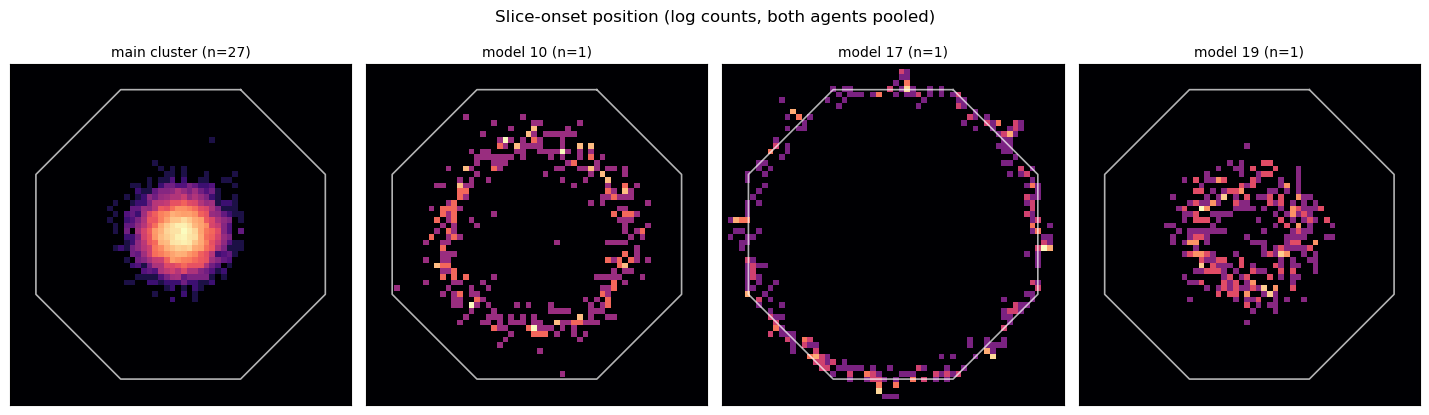

In [13]:
HIST_BINS = 60
R = mc.ARENA_RADIUS
extent = [-R, R, -R, R]
hrange = [[-R, R], [-R, R]]
slice_df['group'] = slice_df['model'].map(model_meta.set_index('model')['group'])

oct_x, oct_y = plot_octagon.calculate_coordinates(vertex=True)
panels = [('main cluster', slice_df[slice_df['group'] == 'main'], len(MAIN))]
panels += [(f'model {m}', slice_df[slice_df['model'] == m], 1) for m in OUTLIERS]

fig, axes = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 4.2))
for ax, (lab, sub, n) in zip(np.atleast_1d(axes), panels):
    H, _, _ = np.histogram2d(sub['x'].to_numpy(float), sub['z'].to_numpy(float),
                             bins=HIST_BINS, range=hrange)
    ax.imshow(np.log1p(H).T, origin='lower', extent=extent, cmap='magma', aspect='equal')
    ax.plot(oct_x, oct_y, color='white', lw=1.2, alpha=0.7)
    ax.set_title(f'{lab} (n={n})', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Slice-onset position (log counts, both agents pooled)', y=1.0)
plt.tight_layout(); plt.show()

### When a wall first comes into view

Cumulative proportion of trials with a trial wall in the FoV, measured from slice onset. A trial
that ended before a wall came into view never counts as seen, so each curve plateaus at
`1 - frac_never_visible` rather than reaching 1. The lower panel gives the share of trials still
running, which is what makes that plateau readable.

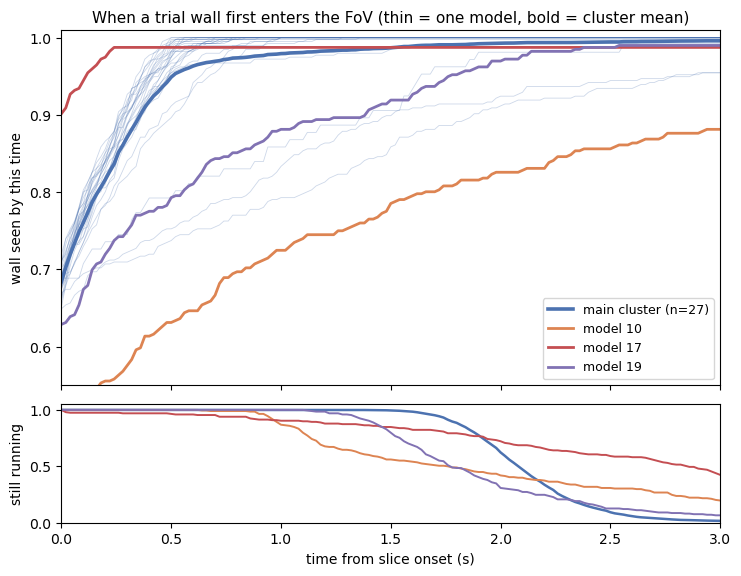

In [14]:
# take the cumulative visibility curve for every model
curve = mc.wall_visible_curve(tables['vis'], max_s=3.0)
curve = curve.merge(model_meta[['model', 'group']], on='model')

fig, (ax, axr) = plt.subplots(2, 1, figsize=(8.5, 6.4), sharex=True,
                              gridspec_kw=dict(height_ratios=[3, 1], hspace=0.08))
# plot one thin line per main-cluster model, so the within-cluster spread stays visible
main_curve = curve[curve['group'] == 'main']
for _, g in main_curve.groupby('model'):
    ax.plot(g['t'], g['p_visible'], color='#4C72B0', lw=0.6, alpha=0.28)
m = main_curve.groupby('t')[['p_visible', 'p_running']].mean()
ax.plot(m.index, m['p_visible'], color='#4C72B0', lw=2.6, label=f'main cluster (n={len(MAIN)})')
axr.plot(m.index, m['p_running'], color='#4C72B0', lw=1.8)

# plot each off-cluster model on its own
for mod in OUTLIERS:
    g = curve[curve['model'] == mod]
    ax.plot(g['t'], g['p_visible'], color=OUT_COLOURS[mod], lw=2.0, label=f'model {mod}')
    axr.plot(g['t'], g['p_running'], color=OUT_COLOURS[mod], lw=1.4)

ax.set_ylim(0.55, 1.01); ax.set_ylabel('wall seen by this time')
ax.set_title('When a trial wall first enters the FoV (thin = one model, bold = cluster mean)',
             fontsize=11)
ax.legend(fontsize=9, loc='lower right')
axr.set_ylim(0, 1.05); axr.set_xlim(0, 3)
axr.set_ylabel('still running'); axr.set_xlabel('time from slice onset (s)')
plt.show()

## Stage 3 - multivariate fingerprint

PCA of the standardised metrics, with the two centrality columns left out, shows what else
separates these models once position is removed. A PC1 that still tracks centrality means the
off-cluster models differ in everything at once. A PC1 that does not means the batch varies on
something independent of where the agents stand.

PC1 explains 38%, PC2 23% of fingerprint variance
corr(PC1, slice-onset centrality) = -0.30  (|r|~1 => centrality is the main axis; ~0 => something else is)


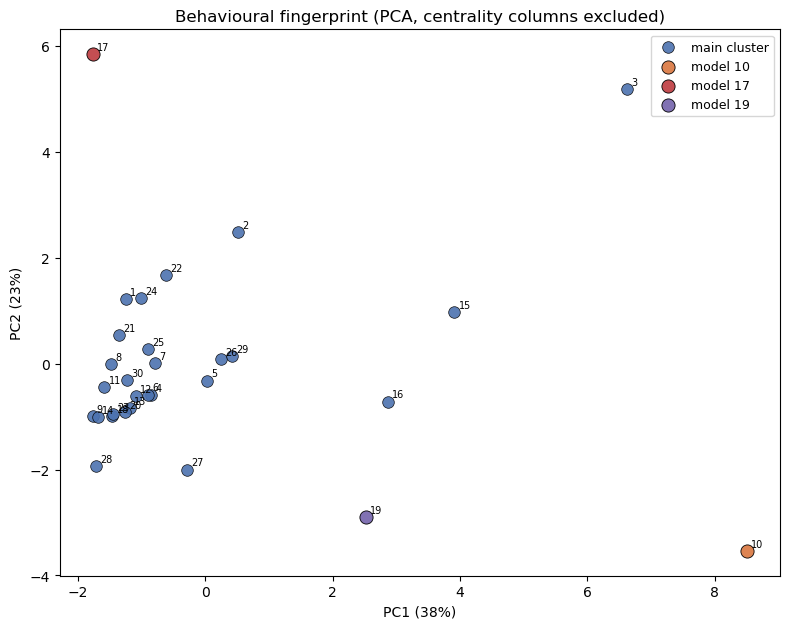

In [15]:
fingerprint, pca = mc.add_fingerprint_pca(fingerprint)
mc.report_pca(fingerprint, pca)

fig, ax = plt.subplots(figsize=(8, 6.4))
ax.scatter(fingerprint.loc[fingerprint['group'] == 'main', 'pc1'],
           fingerprint.loc[fingerprint['group'] == 'main', 'pc2'],
           s=70, color='#4C72B0', edgecolor='black', linewidth=0.5, label='main cluster', alpha=0.9)
for mod in OUTLIERS:
    r = fingerprint[fingerprint['model'] == mod].iloc[0]
    ax.scatter(r['pc1'], r['pc2'], s=90, color=OUT_COLOURS[mod], edgecolor='black',
               linewidth=0.6, label=f'model {mod}', zorder=5)
for _, r in fingerprint.iterrows():
    ax.annotate(int(r['model']), (r['pc1'], r['pc2']), fontsize=7, xytext=(3, 3),
                textcoords='offset points')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
ax.set_title('Behavioural fingerprint (PCA, centrality columns excluded)')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

In [16]:
# show which metrics load on each component, so the axes can be read
loadings = pd.DataFrame(pca.components_.T, index=mc.PCA_METRICS, columns=['pc1', 'pc2'])
loadings.reindex(loadings['pc1'].abs().sort_values(ascending=False).index).round(2)

,pc1,pc2
all_latency_to_wall_visible,0.40,-0.07
late_latency_to_wall_visible,0.40,0.00
frac_never_visible,0.36,-0.01
frac_trials_over_5s,0.32,-0.10
rot_total,-0.30,-0.15
prop_no_rotational,0.30,0.15
frac_visible_at_onset,-0.24,0.31
score_rate,-0.22,-0.22
mean_score,-0.22,0.09
p_high,-0.20,0.22


## Stage 4 - against 260723

260723's central group is the right comparison, as this batch is almost all central. Those means
are taken from the 260723 notebook's between-strategy table. The comparison is descriptive: the
two batches differ in five training settings at once, so no single one can be credited.

In [17]:
# 260723 central-group means, read off the between-strategy table in the 260723 notebook
CENTRAL_260723 = {
    'onset_centrality': 0.849, 'iti_centrality': 0.778, 'prop_no_translational': 0.128,
    'prop_no_rotational': 0.192, 'proportion_resting': 0.027, 'iti_path_len': 43.229,
    'rot_total': 1448.079, 'winner_path_len': 20.446, 'path_ratio': 1.152,
    'frac_visible_at_onset': 0.684, 'late_latency_to_wall_visible': 0.299,
    'all_latency_to_wall_visible': 0.095, 'latency_to_reach_wall': 2.055,
    'frac_never_visible': 0.000, 'frac_trials_over_5s': 0.000, 'p_high': 0.862,
    'mean_score': 0.462, 'score_rate': 0.442,
}

# compare on the main cluster only. The median is carried alongside the mean, as a few models
# pull the resting metrics hard
cmp = pd.DataFrame(dict(
    metric=mc.FP_METRICS,
    central_260723=[CENTRAL_260723[m] for m in mc.FP_METRICS],
    main_260914=[fp_main[m].mean() for m in mc.FP_METRICS],
    median_260914=[fp_main[m].median() for m in mc.FP_METRICS],
))
cmp['change'] = cmp['main_260914'] - cmp['central_260723']
# express the change relative to the 260723 value, where that value is not at the floor
cmp['pct'] = np.where(cmp['central_260723'].abs() > 1e-3,
                      100 * cmp['change'] / cmp['central_260723'], np.nan)
cmp.reindex(cmp['pct'].abs().sort_values(ascending=False).index).round(3)

,metric,central_260723,main_260914,median_260914,change,pct
4,proportion_resting,0.027,0.053,0.026,0.026,95.313
2,prop_no_translational,0.128,0.187,0.109,0.059,46.448
3,prop_no_rotational,0.192,0.229,0.193,0.037,19.231
10,late_latency_to_wall_visible,0.299,0.341,0.243,0.042,14.206
15,p_high,0.862,0.975,1.000,0.113,13.082
11,all_latency_to_wall_visible,0.095,0.107,0.075,0.012,12.765
16,mean_score,0.462,0.501,0.505,0.039,8.407
1,iti_centrality,0.778,0.837,0.838,0.059,7.554
5,iti_path_len,43.229,40.041,43.910,-3.188,-7.374
17,score_rate,0.442,0.464,0.468,0.022,5.063


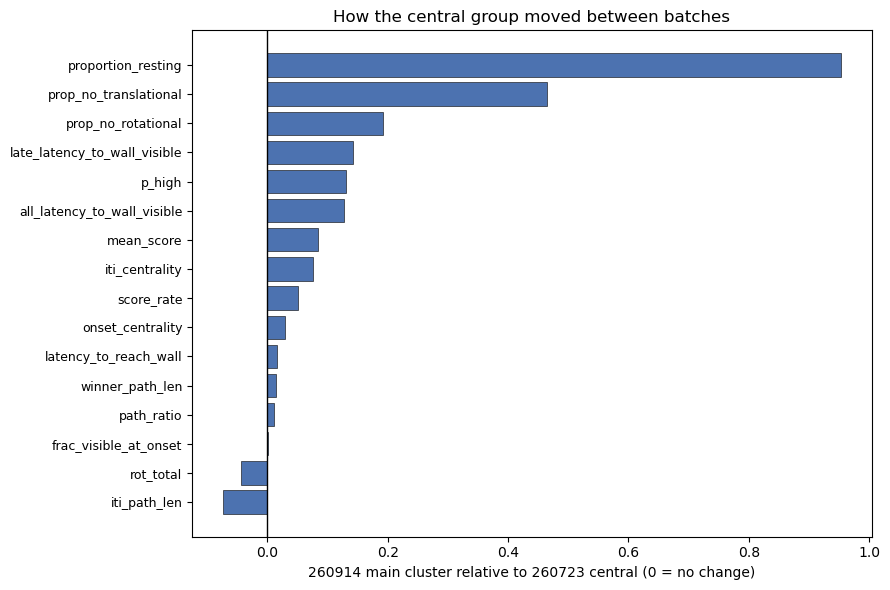

In [18]:
# plot the metrics side by side, each scaled by the 260723 central value so they share an axis
plot_metrics = [m for m in mc.FP_METRICS if abs(CENTRAL_260723[m]) > 1e-3]
ratio = [fp_main[m].mean() / CENTRAL_260723[m] for m in plot_metrics]
order = np.argsort(ratio)

fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(plot_metrics))
ax.barh(y, [ratio[i] - 1 for i in order], color='#4C72B0', edgecolor='black', linewidth=0.4)
ax.axvline(0, color='black', lw=1)
ax.set_yticks(y); ax.set_yticklabels([plot_metrics[i] for i in order], fontsize=9)
ax.set_xlabel('260914 main cluster relative to 260723 central (0 = no change)')
ax.set_title('How the central group moved between batches')
plt.tight_layout(); plt.show()

## Stage 5 - tournament field

The tournament asks whether the stronger High-wall preference in this batch earns more reward per
second **in competition**. 260914 central models choose High on almost every trial
(`p_high` ~1.00); 260723 central models choose it about 85% of the time.

Self-play cannot answer it. `score_rate` sums `winner_score`, which is 1.0 for a High trigger and
0.4 for a Low one, so choosing High raises the score rate by construction. Both agents are also the
same model, so there is no opponent with a different policy to lose the race to. The correlation
below is reported for the record, not as evidence.

The field is two typical 260914 central models, two typical 260723 central models, and the one
off-cluster 260914 model. "Typical" is distance to the batch's own central-cluster centre in
standardised metric space, the measure `mc.medoid_model` uses for one model, extended to a ranking.
It is computed twice, on the full fingerprint and again with the centrality columns removed, so a
model that is only typical because of where it stands does not win on that alone.

In [19]:
from scipy import stats
from sklearn.preprocessing import StandardScaler

# report how p_high tracks scoring within the cluster. This is mechanically confounded, as
# score_rate is built from the same High/Low outcome p_high counts, so it cannot stand alone
for y in ('score_rate', 'mean_score'):
    r, p = stats.pearsonr(fp_main['p_high'], fp_main[y])
    print(f"p_high vs {y:12s}  r = {r:+.2f}  (p = {p:.3f})  <- partly mechanical")

p_high vs score_rate    r = +0.59  (p = 0.001)  <- partly mechanical
p_high vs mean_score    r = +0.46  (p = 0.017)  <- partly mechanical


In [20]:
def typicality(sub, metrics):
    """ Return each model's distance to the group centre in standardised metric space.
        Takes a slice of the fingerprint table and the metrics to use. """

    X = sub[metrics].astype(float)
    z = StandardScaler().fit_transform(X.fillna(X.mean()))
    return pd.Series(np.linalg.norm(z - z.mean(0), axis=1), index=sub['model'].astype(int))


def typicality_rank(sub):
    """ Return the group ranked from most to least typical. Takes a slice of the fingerprint. """

    r = pd.DataFrame({'dist_all': typicality(sub, mc.FP_METRICS),
                      'dist_beh': typicality(sub, mc.PCA_METRICS)})
    r['mean_rank'] = (r['dist_all'].rank() + r['dist_beh'].rank()) / 2
    r['p_high'] = sub.set_index(sub['model'].astype(int))['p_high']
    r['score_rate'] = sub.set_index(sub['model'].astype(int))['score_rate']
    return r.sort_values('mean_rank')


rank = typicality_rank(fp_main)
rank['n_trials'] = n_trials
print("most typical 260914 central models (lower dist = nearer the cluster centre)")
rank.head(6).round(3)

most typical 260914 central models (lower dist = nearer the cluster centre)


,dist_all,dist_beh,mean_rank,p_high,score_rate,n_trials
model,,,,,,
20,2.044,2.030,1.0,1.0,0.488,198
14,2.332,2.270,3.5,1.0,0.473,198
13,2.427,2.155,3.5,1.0,0.477,198
23,2.407,2.342,5.0,1.0,0.477,198
7,2.441,2.367,7.0,1.0,0.468,198
12,2.649,2.325,7.0,1.0,0.466,198


In [21]:
CENTRAL_PICKS = rank.index[:2].tolist()
FIELD_260914 = CENTRAL_PICKS + [17]
print(f"260914 central picks: {CENTRAL_PICKS}")
print(f"260914 entrants:      {FIELD_260914}")

# check the picks really are average, rather than only similar to each other. z is SDs from the
# main-cluster mean, so a pick sitting inside +/-1 on every metric is typical on all of them
rows = []
for m in mc.FP_METRICS:
    mu, sd = fp_main[m].mean(), fp_main[m].std()
    r = dict(metric=m, cluster_mean=mu, cluster_median=fp_main[m].median())
    for p in FIELD_260914:
        r[f'z{p}'] = (fingerprint.loc[fingerprint.model == p, m].iloc[0] - mu) / sd if sd else 0.0
    rows.append(r)
zt = pd.DataFrame(rows)
print()
for p in FIELD_260914:
    z = zt[f'z{p}'].abs()
    print(f"model {p:2d}: max |z| = {z.max():6.2f} on {zt.loc[z.idxmax(), 'metric']}")
zt.round(2)

260914 central picks: [20, 14]
260914 entrants:      [20, 14, 17]

model 20: max |z| =   0.96 on score_rate
model 14: max |z| =   1.09 on prop_no_rotational
model 17: max |z| =  31.31 on onset_centrality


,metric,cluster_mean,cluster_median,z20,z14,z17
0,onset_centrality,0.87,0.88,-0.15,0.27,-31.31
1,iti_centrality,0.84,0.84,-0.18,0.45,-21.62
2,prop_no_translational,0.19,0.11,-0.67,-0.74,-0.04
3,prop_no_rotational,0.23,0.19,-0.11,-1.09,-1.27
4,proportion_resting,0.05,0.03,-0.38,-0.53,-0.49
5,iti_path_len,40.04,43.91,0.67,0.72,-0.11
6,rot_total,1383.39,1447.13,0.12,1.08,1.25
7,winner_path_len,20.73,20.77,-0.48,0.06,7.92
8,path_ratio,1.16,1.16,-0.39,-0.13,7.10
9,frac_visible_at_onset,0.68,0.68,0.27,-0.40,11.56


### The 260723 half of the field

The same typicality ranking on 260723's central group, so both batches' entrants are chosen the
same way. This loads the 260723 batch fresh, which is the slow cell in this notebook.

Only two 260723 central models are available to enter: `0034` and `0039` are the only central
models in `results/2607/260723_frozen_3e6`, the snapshot whose policies the `p_high` = 0.86
measurement was taken on. The live 260723 runs have since been extended to 4e6 and are different
models, so a more typical candidate from the live dirs would not be the model characterised here.

In [22]:
# load the 260723 batch and rank its central group the same way
SIM_260723 = os.path.join(data_strings.SIM_DATA_FOLDER, '2607', '260723')
tables_723 = mc.collect_model_data(SIM_260723, fov=CURRENT_FOV, verbose=False)
onset_723, gmm_723, _ = mc.split_strategies(mc.onset_centrality_by_model(tables_723['slice']))
meta_723 = mc.build_model_meta(mc.summarise_collection(tables_723, mc.get_batch_models(SIM_260723),
                                                       verbose=False), onset_723)
fp_723 = mc.build_fingerprint(meta_723, tables_723)

central_723 = fp_723[fp_723['strategy'] == 'central']
rank_723 = typicality_rank(central_723)
print(f"260723 central group (n={len(central_723)}), most typical first")
print(rank_723.head(6).round(3).to_string())

# the only two central models in the frozen snapshot, so the only two that can enter
PICKS_260723 = [34, 39]
order = list(rank_723.index)
print()
for m in PICKS_260723:
    print(f"model {m}: typicality rank {order.index(m) + 1} of {len(order)}, "
          f"p_high {rank_723.loc[m, 'p_high']:.3f}")

260723 central group (n=25), most typical first
       dist_all  dist_beh  mean_rank  p_high  score_rate
model                                                   
34        1.710     1.561        1.0   0.843       0.442
30        2.169     1.706        2.0   0.859       0.452
55        2.437     2.391        4.0   0.859       0.443
11        2.446     1.928        4.0   0.884       0.453
37        2.481     2.468        5.5   0.843       0.427
49        3.188     1.721        5.5   0.854       0.431

model 34: typicality rank 1 of 25, p_high 0.843
model 39: typicality rank 9 of 25, p_high 0.808


In [23]:
# set the two batches' central groups side by side on the metric the tournament is about
print(f"260914 central p_high: mean {fp_main['p_high'].mean():.3f}  "
      f"median {fp_main['p_high'].median():.3f}  range {fp_main['p_high'].min():.3f}-{fp_main['p_high'].max():.3f}")
print(f"260723 central p_high: mean {central_723['p_high'].mean():.3f}  "
      f"median {central_723['p_high'].median():.3f}  range {central_723['p_high'].min():.3f}-{central_723['p_high'].max():.3f}")

# 260914 has low-p_high central models of its own, which would vary High preference with the
# training settings and step count held fixed
low = fp_main.nsmallest(3, 'p_high')[['model', 'p_high', 'score_rate', 'onset_centrality']]
print("\n260914 central models with the lowest High preference, for a controlled follow-up:")
print(low.round(3).to_string(index=False))

260914 central p_high: mean 0.975  median 1.000  range 0.773-1.000
260723 central p_high: mean 0.862  median 0.859  range 0.778-1.000

260914 central models with the lowest High preference, for a controlled follow-up:
 model  p_high  score_rate  onset_centrality
    26   0.773       0.399             0.858
    27   0.788       0.431             0.878
    16   0.849       0.452             0.806


### Does 260914 score better than its High preference alone would give?

Two checks on whether 260914's higher mean score is better play or just the arithmetic of choosing
High more often.

First, compare the two batches at **matched** High preference, restricting both central groups to
`p_high` in [0.74, 0.87]. If 260914 models are better players, they should out-score 260723 models
that choose High just as often.

Second, predict every model's mean score from `p_high` with no fitted parameters. In self-play both
agents run the same policy, so each wins about half the trials. Terminal score is 1.0 for High, 0.4
for Low and 0 for losing the race, which gives
`predicted = 0.5 * (0.4 + 0.6 * p_high)`. A residual near zero for both batches means the score is
fully accounted for by the choice.

In [24]:
LO, HI = 0.74, 0.87                 # the band where the two batches overlap on High preference
cols = ['model', 'p_high', 'mean_score', 'score_rate', 'latency_to_reach_wall', 'onset_centrality']

band_914 = fp_main[fp_main['p_high'].between(LO, HI)]
band_723 = central_723[central_723['p_high'].between(LO, HI)]

print(f"260723 central with p_high in [{LO}, {HI}]  (n={len(band_723)})")
print(band_723[cols].sort_values('p_high').round(3).to_string(index=False))
print(f"\n260914 central with p_high in [{LO}, {HI}]  (n={len(band_914)})")
print(band_914[cols].sort_values('p_high').round(3).to_string(index=False))

print("\nmatched-p_high comparison")
for nm, s in (('260723', band_723), ('260914', band_914)):
    print(f"  {nm}  n={len(s):2d}  p_high {s.p_high.mean():.3f}  mean_score {s.mean_score.mean():.3f}  "
          f"score_rate {s.score_rate.mean():.3f}  latency {s.latency_to_reach_wall.mean():.3f}")
print("\nwhole central groups, for contrast")
for nm, s in (('260723', central_723), ('260914', fp_main)):
    print(f"  {nm}  n={len(s):2d}  p_high {s.p_high.mean():.3f}  mean_score {s.mean_score.mean():.3f}  "
          f"score_rate {s.score_rate.mean():.3f}")

260723 central with p_high in [0.74, 0.87]  (n=18)
 model  p_high  mean_score  score_rate  latency_to_reach_wall  onset_centrality
     4   0.778       0.389       0.439                  1.944             0.865
    39   0.808       0.478       0.436                  2.020             0.875
     9   0.818       0.438       0.434                  2.034             0.841
    13   0.823       0.423       0.409                  2.167             0.831
    14   0.823       0.411       0.446                  1.967             0.876
    15   0.828       0.523       0.419                  2.136             0.854
    32   0.843       0.494       0.432                  2.087             0.851
    24   0.843       0.456       0.460                  1.953             0.874
    34   0.843       0.477       0.442                  2.053             0.854
    37   0.843       0.471       0.427                  2.113             0.860
    49   0.854       0.484       0.431                  2.087        

In [25]:
# predict mean score from p_high alone, with no fitted parameters
both = pd.concat([fp_main[['model', 'p_high', 'mean_score']].assign(batch='260914'),
                  central_723[['model', 'p_high', 'mean_score']].assign(batch='260723')],
                 ignore_index=True)
both['predicted'] = 0.5 * (0.4 + 0.6 * both['p_high'])
both['residual'] = both['mean_score'] - both['predicted']

print(f"mean abs error = {both['residual'].abs().mean():.4f} on scores around "
      f"{both['mean_score'].mean():.2f}")
print("\nresidual by batch (positive = scoring above what its High preference implies)")
print(both.groupby('batch')['residual'].agg(['mean', 'std', 'count']).round(4).to_string())

t, p = stats.ttest_ind(both[both.batch == '260914'].residual,
                       both[both.batch == '260723'].residual)
print(f"\nbatch difference in residual: t = {t:+.2f}, p = {p:.3f}")

mean abs error = 0.0310 on scores around 0.48

residual by batch (positive = scoring above what its High preference implies)
          mean     std  count
batch                        
260723  0.0033  0.0395     25
260914  0.0084  0.0402     27

batch difference in residual: t = +0.46, p = 0.647


Neither batch scores above what its High preference implies, and the residual does not differ
between them. 260914's higher mean score is the consequence of choosing High more often, not better
play. Self-play cannot take this further: the score is set by the choice rather than earned against
an opponent, and both agents share the policy, so there is no one to lose the race to. That is the
question the tournament exists to answer.

### Step-matched check at 4e6

The two batches finish at different training lengths, 7e6 for 260914 and 3e6 for 260723, so the
High-preference gap could be training length rather than the changed settings. To separate them,
five models were re-simulated from their ~4e6 checkpoints by
`agent_training/run_stepmatch_4e6.ipynb`, and are loaded here.

Two questions. Does the `p_high` contrast survive step-matching, which decides whether a
step-matched tournament tests anything? And does 260914's scoring advantage survive it?

In [26]:
# load the 4e6 self-play sims, one folder per batch
STEPMATCH_ROOT = '/home/tom/Unity/Octagon/simulations/stepmatch_4e6'

fp_4e6 = []
for batch in ('260914', '260723'):
    folder = os.path.join(STEPMATCH_ROOT, batch)
    tb = mc.collect_model_data(folder, fov=CURRENT_FOV, verbose=False)
    meta_b = (pd.DataFrame({'model': mc.summarise_collection(tb, mc.get_batch_models(folder),
                                                             verbose=False)})
              .merge(mc.onset_centrality_by_model(tb['slice'])[['model', 'onset_centrality', 'onset_sd']],
                     on='model'))
    meta_b['strategy'] = 'na'
    fp_4e6.append(mc.build_fingerprint(meta_b, tb).assign(batch=batch))
fp_4e6 = pd.concat(fp_4e6, ignore_index=True)

# set each model's 4e6 numbers beside its finished-policy numbers
final = pd.concat([fp_main.assign(batch='260914'), central_723.assign(batch='260723'),
                   fingerprint[fingerprint.model == 17].assign(batch='260914')], ignore_index=True)
cmp4 = fp_4e6.merge(final[['batch', 'model', 'p_high', 'onset_centrality', 'mean_score', 'score_rate']],
                    on=['batch', 'model'], suffixes=('_4e6', '_final'))
cmp4['entrant'] = cmp4['batch'] + '_' + cmp4['model'].astype(int).map('{:04d}'.format)

print("High preference and centrality: finished policy vs 4e6")
print(cmp4[['entrant', 'p_high_final', 'p_high_4e6', 'onset_centrality_final',
            'onset_centrality_4e6']].round(3).to_string(index=False))

High preference and centrality: finished policy vs 4e6
    entrant  p_high_final  p_high_4e6  onset_centrality_final  onset_centrality_4e6
260914_0005         1.000       0.929                   0.900                 0.822
260914_0007         1.000       1.000                   0.885                 0.896
260914_0012         1.000       1.000                   0.878                 0.868
260914_0013         1.000       0.944                   0.852                 0.839
260914_0014         1.000       1.000                   0.880                 0.784
260914_0017         0.965       0.864                   0.140                 0.065
260914_0020         1.000       1.000                   0.870                 0.890
260914_0021         1.000       1.000                   0.893                 0.877
260914_0023         1.000       1.000                   0.878                 0.861
260723_0034         0.843       0.838                   0.854                 0.880
260723_0039         0

In [27]:
# compare the two central groups at 4e6, the like-for-like version of the earlier comparison
CENTRAL_4E6 = [20, 14, 34, 39]
c4 = fp_4e6[fp_4e6['model'].isin(CENTRAL_4E6)]
print("central models at 4e6")
for bt in ('260914', '260723'):
    s = c4[c4['batch'] == bt]
    print(f"  {bt}  n={len(s)}  p_high {s.p_high.mean():.3f}  "
          f"mean_score {s.mean_score.mean():.3f}  score_rate {s.score_rate.mean():.3f}")
print("\nthe same groups at their finished policies, for contrast")
print(f"  260914  n={len(fp_main)}  p_high {fp_main.p_high.mean():.3f}  "
      f"mean_score {fp_main.mean_score.mean():.3f}  score_rate {fp_main.score_rate.mean():.3f}")
print(f"  260723  n={len(central_723)}  p_high {central_723.p_high.mean():.3f}  "
      f"mean_score {central_723.mean_score.mean():.3f}  score_rate {central_723.score_rate.mean():.3f}")

# score each 4e6 model against what its own High preference arithmetically implies
c = fp_4e6.copy()
c['entrant'] = c['batch'] + '_' + c['model'].astype(int).map('{:04d}'.format)
c['predicted'] = 0.5 * (0.4 + 0.6 * c['p_high'])
c['residual'] = c['mean_score'] - c['predicted']
print("\nscoring at 4e6 against the p_high prediction")
print(c[['entrant', 'p_high', 'mean_score', 'predicted', 'residual',
         'score_rate']].round(3).to_string(index=False))

central models at 4e6
  260914  n=2  p_high 1.000  mean_score 0.457  score_rate 0.443
  260723  n=2  p_high 0.806  mean_score 0.459  score_rate 0.438

the same groups at their finished policies, for contrast
  260914  n=27  p_high 0.975  mean_score 0.501  score_rate 0.464
  260723  n=25  p_high 0.862  mean_score 0.462  score_rate 0.442

scoring at 4e6 against the p_high prediction
    entrant  p_high  mean_score  predicted  residual  score_rate
260914_0005   0.929       0.458      0.479    -0.021       0.429
260914_0007   1.000       0.535      0.500     0.035       0.403
260914_0012   1.000       0.510      0.500     0.010       0.425
260914_0013   0.944       0.530      0.483     0.047       0.390
260914_0014   1.000       0.490      0.500    -0.010       0.437
260914_0017   0.864       0.438      0.459    -0.021       0.320
260914_0020   1.000       0.424      0.500    -0.076       0.449
260914_0021   1.000       0.525      0.500     0.025       0.422
260914_0023   1.000       0.480

The `p_high` contrast holds at matched training: 1.000 for the 260914 central pair against 0.806 for
the 260723 pair. High preference is also stable across training, with models 20 and 14 at 1.000 at
both 4e6 and 7e6, so the gap comes from the changed settings rather than from training longer. A
step-matched tournament therefore has a real contrast to test.

The scoring advantage does not hold. At their finished policies 260914 central out-scored 260723
(`mean_score` 0.501 against 0.462), but at 4e6 the two groups are level (0.457 against 0.459) despite
the 0.19 gap in `p_high`. The residuals lean the same way, with the 260914 models scoring slightly
below what their High preference implies and the 260723 models slightly above. This rests on two
models per batch, so it is a hint rather than a result, and it is self-play either way.

One caveat for the field: `260914_0014` sits at centrality 0.784 at 4e6, just below its batch's main
band of 0.81-0.91. It is still clearly central next to model 17 at 0.065, but it is at the edge.

### 260914 at 4e6 against its own finished policy

The 4e6 numbers above are a snapshot partway through training, not the models' end state. Nine
260914 models were simulated at both 4e6 and 7e6, so the two can be compared directly, model by
model. `n_up` and `n_down` count how many of the eight central models moved each way, which matters
more than the p-value on eight paired points.

In [28]:
# pair each model's 4e6 numbers with its own 7e6 numbers. Same seeds, so this is a within-model
# comparison of what the last 3e6 steps changed
paired = (fp_4e6[fp_4e6['batch'] == '260914'][['model'] + mc.FP_METRICS]
          .merge(fingerprint[['model'] + mc.FP_METRICS], on='model', suffixes=('_4e6', '_7e6')))
paired_central = paired[paired['model'] != 17]
print(f"models simulated at both checkpoints: {sorted(paired['model'].astype(int))}")

rows = []
for m in mc.FP_METRICS:
    delta = paired_central[f'{m}_7e6'] - paired_central[f'{m}_4e6']
    t, pv = stats.ttest_rel(paired_central[f'{m}_7e6'], paired_central[f'{m}_4e6'])
    rows.append(dict(metric=m, at_4e6=paired_central[f'{m}_4e6'].mean(),
                     at_7e6=paired_central[f'{m}_7e6'].mean(), change=delta.mean(),
                     n_up=int((delta > 0).sum()), n_down=int((delta < 0).sum()), p=pv))
dev = pd.DataFrame(rows)
dev['pct'] = 100 * dev['change'] / dev['at_4e6'].abs()
print(f"\n260914 central models (n={len(paired_central)}), paired 4e6 -> 7e6")
print(dev.sort_values('p')[['metric', 'at_4e6', 'at_7e6', 'change', 'pct',
                            'n_up', 'n_down', 'p']].round(3).to_string(index=False))

models simulated at both checkpoints: [5, 7, 12, 13, 14, 17, 20, 21, 23]

260914 central models (n=8), paired 4e6 -> 7e6
                      metric   at_4e6   at_7e6  change     pct  n_up  n_down     p
                  path_ratio    1.278    1.168  -0.110  -8.578     0       8 0.000
       latency_to_reach_wall    2.305    2.091  -0.214  -9.293     0       8 0.000
                  score_rate    0.423    0.475   0.052  12.331     8       0 0.000
             winner_path_len   22.751   20.760  -1.991  -8.751     0       8 0.000
late_latency_to_wall_visible    0.465    0.243  -0.222 -47.698     0       8 0.001
 all_latency_to_wall_visible    0.149    0.075  -0.074 -49.412     0       8 0.001
          proportion_resting    0.036    0.020  -0.017 -46.400     1       7 0.007
              iti_centrality    0.767    0.853   0.087  11.287     7       1 0.007
                   rot_total 1257.007 1440.007 183.000  14.558     7       1 0.056
          prop_no_rotational    0.299    0.198  -

Between 4e6 and 7e6 these models learn **efficiency, not choice**. High preference is already
saturated at 4e6 and barely moves. What improves is the route: every one of the eight gets more
direct, faster to the wall and higher scoring per second, with no exceptions in either direction.

So the earlier cross-batch comparison caught 260914 mid-learning. The question that follows is
whether 260723 was still improving at 4e6 too, or had already finished.

### Had 260723 finished by 4e6?

Its two entrants were simulated at 3e6 for the original characterisation and again at 4e6 here, so
the same paired comparison is available. `max_steps` for that batch was 4e6, so 4e6 is its end
state.

In [29]:
# compare each 260723 entrant against itself a million steps earlier
watch = ['p_high', 'path_ratio', 'winner_path_len', 'latency_to_reach_wall', 'score_rate',
         'onset_centrality']
r4 = fp_4e6[fp_4e6['batch'] == '260723']
for m in sorted(r4['model'].astype(int)):
    a = central_723[central_723['model'] == m].iloc[0]
    b = r4[r4['model'] == m].iloc[0]
    print(f"260723_{m:04d}   3e6 -> 4e6")
    for k in watch:
        print(f"   {k:24s} {a[k]:8.3f} -> {b[k]:8.3f}   ({b[k] - a[k]:+.3f})")
    print()

260723_0034   3e6 -> 4e6
   p_high                      0.843 ->    0.838   (-0.005)
   path_ratio                  1.131 ->    1.129   (-0.002)
   winner_path_len            20.144 ->   20.042   (-0.101)
   latency_to_reach_wall       2.053 ->    2.007   (-0.046)
   score_rate                  0.442 ->    0.444   (+0.002)
   onset_centrality            0.854 ->    0.880   (+0.026)

260723_0039   3e6 -> 4e6
   p_high                      0.808 ->    0.773   (-0.035)
   path_ratio                  1.130 ->    1.116   (-0.014)
   winner_path_len            19.956 ->   19.739   (-0.216)
   latency_to_reach_wall       2.020 ->    1.967   (-0.053)
   score_rate                  0.436 ->    0.432   (-0.005)
   onset_centrality            0.875 ->    0.844   (-0.031)



260723 is flat over its last million steps: route directness and score rate move by under 1.5%,
in both directions. It had converged. 260914 at 4e6 had not.

That makes the two comparisons answer different questions, and they do not agree.

In [30]:
# the same central models under both framings
a4 = fp_4e6[(fp_4e6['batch'] == '260914') & (fp_4e6['model'] != 17)]
a7 = fingerprint[fingerprint['model'].isin(a4['model'])]
r4 = fp_4e6[fp_4e6['batch'] == '260723']

print(f"{'metric':<26}{'260914 @4e6':>13}{'260914 @7e6':>13}{'260723 @4e6':>13}")
for k in ('p_high', 'path_ratio', 'latency_to_reach_wall', 'score_rate', 'mean_score'):
    print(f"{k:<26}{a4[k].mean():>13.3f}{a7[k].mean():>13.3f}{r4[k].mean():>13.3f}")
print("\n260914 @7e6 and 260723 @4e6 are each batch's finished policy;")
print("260914 @4e6 is the same models partway through training.")

metric                      260914 @4e6  260914 @7e6  260723 @4e6
p_high                            0.984        1.000        0.806
path_ratio                        1.278        1.168        1.122
latency_to_reach_wall             2.305        2.091        1.987
score_rate                        0.423        0.475        0.438
mean_score                        0.494        0.501        0.459

260914 @7e6 and 260723 @4e6 are each batch's finished policy;
260914 @4e6 is the same models partway through training.


**Matched on compute (both at 4e6), 260723 wins**: it is more direct (1.122 against 1.278), faster
to the wall and slightly ahead on score per second.

**Matched on convergence (each at its own finished policy), 260914 wins**: score rate 0.475 against
0.438, an 8% lead, with High chosen on every trial. It is still slightly less direct (1.168 against
1.122), so the remaining gap is route efficiency rather than choice.

Both are legitimate and they measure different things. The compute-matched comparison asks which
recipe is further along after the same training; the converged comparison asks which recipe produces
the better model in the end. 260914 learns the task more slowly and finishes higher on score rate.

This changes how the route-inefficiency result should be read. At 4e6 the 260914 models are not
badly-taught navigators, they are unfinished ones, and most of the gap closes by 7e6. A longer
effective horizon (higher gamma and lambda) spreading credit over more steps is a plausible reason
for slower convergence, but nothing here isolates it: five settings moved together, and every 260914
model shares all five.

### Picking the field on 4e6 centrality

Centrality at 4e6 is not the centrality at the finished policy, and does not move in a predictable
direction. So the entrants are chosen on their 4e6 values, and nine 260914 central candidates were
simulated at that checkpoint to choose from.

The pair wanted is the one that leaves all four central entrants most alike on centrality, while
still choosing High on every trial.

In [31]:
import itertools

cand = fp_4e6[(fp_4e6['batch'] == '260914') & (fp_4e6['model'] != 17)]
ref = fp_4e6[fp_4e6['batch'] == '260723']

# try every 260914 pair and score it on how tightly the four central entrants sit together
rows = []
for a, b in itertools.combinations(cand['model'].astype(int), 2):
    sub = cand[cand['model'].isin([a, b])]
    four = ref['onset_centrality'].tolist() + sub['onset_centrality'].tolist()
    rows.append(dict(pair=f"{a},{b}", span=max(four) - min(four), sd=np.std(four, ddof=1),
                     min_p_high=sub['p_high'].min()))
pairs = pd.DataFrame(rows).sort_values('span')

print("260914 pairs that best match the 260723 entrants on 4e6 centrality")
print(pairs.head(6).round(3).to_string(index=False))
best = pairs[pairs['min_p_high'] >= 0.999].iloc[0]
print(f"\nbest pair still choosing High on every trial: {best['pair']}  "
      f"(span {best['span']:.3f}, SD {best['sd']:.3f})")

260914 pairs that best match the 260723 entrants on 4e6 centrality
 pair  span    sd  min_p_high
12,23 0.037 0.015       1.000
21,23 0.037 0.017       1.000
12,21 0.037 0.017       1.000
12,13 0.041 0.020       0.944
13,23 0.041 0.019       0.944
13,21 0.041 0.022       0.944

best pair still choosing High on every trial: 12,23  (span 0.037, SD 0.015)


### The two batches at 4e6, with eight central models a side

The earlier comparison rested on two 260914 models. With eight, the picture sharpens. `mean_score`
is still the arithmetic of High preference, but **speed** separates the batches cleanly.

In [32]:
c4 = fp_4e6[(fp_4e6['batch'] == '260914') & (fp_4e6['model'] != 17)].copy()
r4 = fp_4e6[fp_4e6['batch'] == '260723'].copy()
for s in (c4, r4):
    s['predicted'] = 0.5 * (0.4 + 0.6 * s['p_high'])
    s['residual'] = s['mean_score'] - s['predicted']

both4 = pd.concat([c4, r4])
both4['entrant'] = both4['batch'] + '_' + both4['model'].astype(int).map('{:04d}'.format)
print("central models at 4e6, against what p_high alone predicts")
print(both4.sort_values(['batch', 'score_rate'])[
    ['entrant', 'p_high', 'mean_score', 'predicted', 'residual', 'score_rate',
     'latency_to_reach_wall', 'onset_centrality']].round(3).to_string(index=False))

print()
for nm, s in (('260914', c4), ('260723', r4)):
    print(f"{nm}  n={len(s)}  p_high {s.p_high.mean():.3f}  mean_score {s.mean_score.mean():.3f}  "
          f"residual {s.residual.mean():+.3f}  score_rate {s.score_rate.mean():.3f}  "
          f"latency {s.latency_to_reach_wall.mean():.3f}")

t, pv = stats.ttest_ind(c4['latency_to_reach_wall'], r4['latency_to_reach_wall'])
print(f"\nlatency to wall, 260914 vs 260723: t = {t:+.2f}, p = {pv:.3f}  "
      f"(ranges {c4.latency_to_reach_wall.min():.3f}-{c4.latency_to_reach_wall.max():.3f} vs "
      f"{r4.latency_to_reach_wall.min():.3f}-{r4.latency_to_reach_wall.max():.3f}, no overlap)")
t, pv = stats.ttest_ind(c4['score_rate'], r4['score_rate'])
print(f"score rate,      260914 vs 260723: t = {t:+.2f}, p = {pv:.3f}  "
      f"(n=8 vs 2, so read the size rather than the p)")

central models at 4e6, against what p_high alone predicts
    entrant  p_high  mean_score  predicted  residual  score_rate  latency_to_reach_wall  onset_centrality
260723_0039   0.773       0.456      0.432     0.024       0.432                  1.967             0.844
260723_0034   0.838       0.463      0.452     0.011       0.444                  2.007             0.880
260914_0013   0.944       0.530      0.483     0.047       0.390                  2.430             0.839
260914_0007   1.000       0.535      0.500     0.035       0.403                  2.356             0.896
260914_0021   1.000       0.525      0.500     0.025       0.422                  2.364             0.877
260914_0012   1.000       0.510      0.500     0.010       0.425                  2.336             0.868
260914_0023   1.000       0.480      0.500    -0.020       0.425                  2.330             0.861
260914_0005   0.929       0.458      0.479    -0.021       0.429                  2.176       

Choosing High more often does not make these models better. Every model in both batches lands
within 0.05 of `0.5 * (0.4 + 0.6 * p_high)`, and the group residuals are -0.001 and +0.017, so
`mean_score` is still just the arithmetic of the choice.

What separates the batches is speed. Every 260914 central model is slower to the wall than either
260723 model, with no overlap (2.18-2.43 s against 1.97-2.01 s, t = +4.80, p = 0.001). That wipes
out the High-choice advantage in score per second, where 260914 is slightly behind at 0.423 against
0.438. The 260723 side is only two models, so read the size of the gap rather than the p-value on
score rate; the latency gap is large enough and clean enough to stand on its own.

So at matched training these models choose better, arrive slower, and end up no better off. Being
slow while holding out for High is the combination most likely to lose a race against a live
opponent, which is what the tournament tests.

### Final tournament field, step-matched at 4e6

Every entrant enters at ~4e6 steps, and the four central entrants are matched on centrality at that
step (0.844-0.880, SD 0.015).

260914 central: [12, 23] — `p_high` 1.000, centrality 0.868 and 0.861

260723 central: [34, 39] — `p_high` 0.838 and 0.773, centrality 0.880 and 0.844

Off-cluster: [17] — `p_high` 0.864, centrality 0.065

Candidates were first ranked by typicality within their own batch's central cluster, then nine
260914 central models were simulated at 4e6 and the pair chosen that sits closest to the 260723
entrants while still choosing High on every trial.

**The two batches still differ in more than High preference.** Matching step count and centrality
removes two confounds, not the five changed training settings. The controlled version of this
question is a tournament between 260914's own low-`p_high` central models (26 at 0.773, 27 at 0.788)
and its `p_high` = 1.000 models, where every setting is identical.

Run with `agent_training/tournament/run_tournament_260914.ipynb`.

## Reading the results

- **Stage 1** places every model on one axis, its position when the trial starts. Unlike 260723
  the models do not fall into two groups, so the split is reported and then set aside.
- **Stage 2** asks what separates models inside the one cluster. The metrics with the widest
  spread are the ones that still tell these models apart; the flat ones are fixed by the task.
- **Stage 3** checks whether anything beyond centrality organises the batch.
- **Stage 4** compares the central group across the two batches.

**Caveats.** In self-play, where an agent stands at slice onset depends partly on its opponent,
so centrality reflects both agents, not one model alone. Inference policies are near-deterministic,
so read the per-model points rather than only the cluster mean. Every run here trained for 7e6
steps, so any spread within the batch is seed, not training length. The 260723 comparison moves
five training settings at once and cannot attribute the change to any one of them. Model 16's run
hung early and contributes about a quarter of the trials the others do.